In [32]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.linalg import eigh,cho_factor,cho_solve
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter,LogFormatterMathtext
from matplotlib.colors import LogNorm

In [ ]:
# -------------------- Example settings --------------------
example_name = "Example4"

L,N,dt,T,Ct = np.pi,96,1e-4,0.2,10
m,kappa = 2,0.2

p = dict(
    centers=8,M=8000,seed=123,
    ell_V=0.8,ell_W=0.8,
    lam_V=1e-10,lam_W=1e-10,rank_tol=1e-12
)

# p = dict(
#     centers=8,M=8000,seed=123,
#     ell_V=0.8,ell_W=0.8,
#     lam_V=1e-9,lam_W=1e-9,rank_tol=1e-12
# )

# p = dict(
#     centers=8,M=8000,seed=123,
#     ell_V=0.8,ell_W=0.8,
#     lam_V=1e-11,lam_W=1e-11,rank_tol=1e-12
# )

def V(X,Y):
    return (np.cos(2*X)+0.6*np.cos(2*Y)
            +0.3*np.sin(2*X)*np.sin(2*Y))

def W(X,Y):
    return np.cos(2*X)+0.5*np.cos(2*Y)+np.cos(X)+np.cos(Y)

def rho0(X,Y):
    return (1+0.2*np.cos(2*X)+0.2*np.sin(2*Y)
            +0.1*np.cos(2*X)*np.cos(2*Y))/(2*np.pi)**2

def phi0(X,Y):
    return np.zeros_like(X)

def Uprime(r):
    return kappa*r**(m-1)

def invisible_W(X,Y):
    return np.cos(X)+np.cos(Y)

data_dir = Path(example_name)/"data"
fig_dir = Path(example_name)/"figures"
for folder in (data_dir,fig_dir):
    folder.mkdir(parents=True,exist_ok=True)

def savefig(fig,name):
    for ext in ("png","pdf"):
        fig.savefig(fig_dir/f"{example_name}_{name}.{ext}", dpi=300,bbox_inches="tight")

Flow shape: (201, 96, 96)
Maximum mass error: 3.331e-16
Minimum density: 1.461354e-02
Maximum checked CFL: 0.001104
Half-period symmetry error, x1: 3.851e-16
Half-period symmetry error, x2: 4.441e-16
Final L2 density change: 1.217892e-02
Maximum excitation with an odd index: 2.655e-17
Mode (1,0): 2.647521e-17; mode (0,1): 3.452154e-18
Mode (2,0): 4.415366e-02; mode (0,2): 2.395864e-02
Mode (3,0): 2.323705e-17; mode (0,3): 5.508144e-18
Mode (4,0): 5.599573e-03; mode (0,4): 4.710597e-03


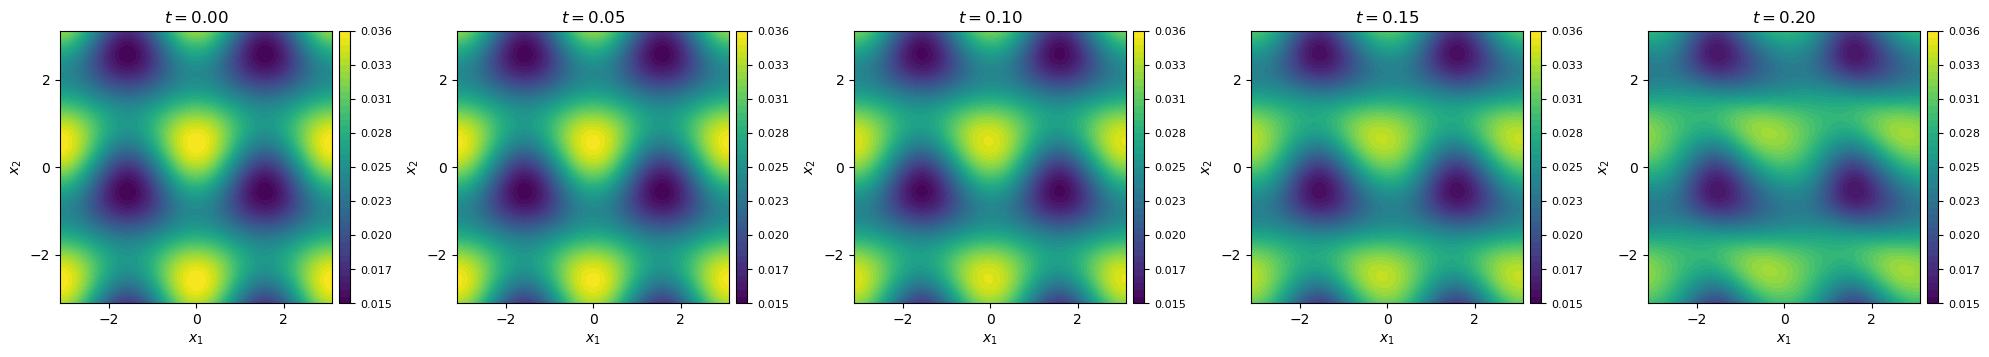

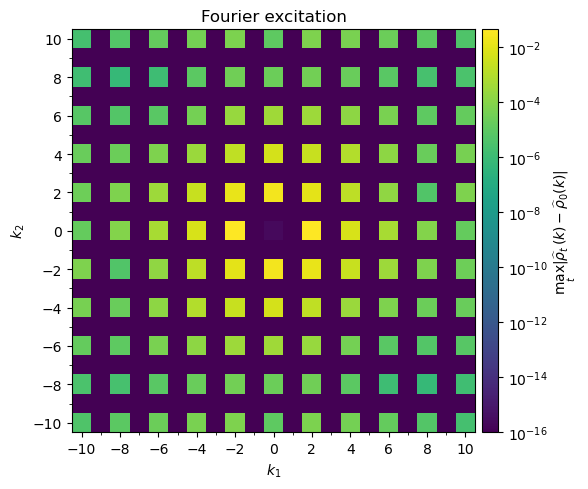

In [34]:
# Periodic 2D Wasserstein Hamiltonian flow.
# Godunov HJ scheme + upwind finite-volume continuity equation.

assert N>=8 and N%2==0 and dt>0 and T>0 and Ct>=1
dx = 2*L/N
n_steps = int(round(T/dt))
assert np.isclose(n_steps*dt,T)

x = -L+(np.arange(N)+0.5)*dx
X,Y = np.meshgrid(x,x,indexing="ij")
lags = np.arange(N)*dx
S1,S2 = np.meshgrid(lags,lags,indexing="ij")

V_values = np.asarray(V(X,Y),dtype=float)
W_values = np.asarray(W(S1,S2),dtype=float)
assert V_values.shape==W_values.shape==(N,N)
assert np.isfinite(V_values).all() and np.isfinite(W_values).all()
V_values -= V_values.mean()
W_values -= W_values.mean()
FW_true = np.fft.fft2(W_values)

def H_godunov(phi):
    H = np.zeros_like(phi)
    rate = 0.0
    for axis in (0,1):
        dm = (phi-np.roll(phi,1,axis=axis))/dx
        dp = (np.roll(phi,-1,axis=axis)-phi)/dx
        H += 0.5*np.maximum(np.maximum(dm,0)**2,np.minimum(dp,0)**2)
        rate += max(np.abs(dm).max(),np.abs(dp).max())/dx
    return H,dt*rate

def density_rhs(r,phi):
    out,rate = np.zeros_like(r),np.zeros_like(r)
    for axis in (0,1):
        u = (np.roll(phi,-1,axis=axis)-phi)/dx
        flux = np.maximum(u,0)*r+np.minimum(u,0)*np.roll(r,-1,axis=axis)
        out -= (flux-np.roll(flux,1,axis=axis))/dx
        rate += (np.maximum(u,0)
                 +np.maximum(-np.roll(u,1,axis=axis),0))/dx
    return out,dt*rate.max()

# -------------------- Initial state --------------------
rho = np.asarray(rho0(X,Y),dtype=float)
phi = np.asarray(phi0(X,Y),dtype=float)
assert rho.shape==phi.shape==(N,N)
assert np.isfinite(rho).all() and rho.min()>0
assert np.isfinite(phi).all()
rho /= rho.sum()*dx**2
phi -= phi.mean()
mass0 = rho.sum()*dx**2

times,rhos,phis = [],[],[]
max_cfl,min_density = 0.0,rho.min()

# -------------------- Time integration --------------------
for n in range(n_steps+1):
    if n%Ct==0 or n==n_steps:
        times.append(n*dt)
        rhos.append(rho.copy())
        phis.append(phi.copy())
    if n==n_steps: break

    H,cfl_hj = H_godunov(phi)
    if not np.isfinite(cfl_hj) or cfl_hj>1:
        raise RuntimeError("HJ CFL violated")

    conv = dx**2*np.fft.ifft2(FW_true*np.fft.fft2(rho)).real
    phi = phi-dt*(H+Uprime(rho)+V_values+conv)
    phi -= phi.mean()

    dr,cfl_rho = density_rhs(rho,phi)
    if not np.isfinite(cfl_rho) or cfl_rho>1:
        raise RuntimeError("Density CFL violated")
    rho = rho+dt*dr

    if not np.isfinite(phi).all() or not np.isfinite(rho).all() or rho.min()<0:
        raise RuntimeError("Invalid flow state")
    max_cfl = max(max_cfl,cfl_hj,cfl_rho)
    min_density = min(min_density,rho.min())

times,rhos,phis = np.asarray(times),np.asarray(rhos),np.asarray(phis)
mass = rhos.sum(axis=(1,2))*dx**2
symmetry_x = np.max(np.abs(rhos-np.roll(rhos,N//2,axis=1)))
symmetry_y = np.max(np.abs(rhos-np.roll(rhos,N//2,axis=2)))

# -------------------- Fourier excitation --------------------
# Integer mode indices; ordinary integral Fourier coefficients.
Kmax = min(10,N//2-1)
modes = np.arange(-Kmax,Kmax+1)
indices = modes%N
K1,K2 = np.meshgrid(modes,modes,indexing="ij")
phase = np.exp(-1j*np.pi/L*(K1+K2)*x[0])

fourier = np.empty((len(times),len(modes),len(modes)),dtype=complex)
for l,r in enumerate(rhos):
    F = np.fft.fft2(r)
    fourier[l] = dx**2*F[np.ix_(indices,indices)]*phase

excitation = np.max(np.abs(fourier-fourier[0]),axis=0)
odd_mask = (K1%2!=0)|(K2%2!=0)
density_change = np.sqrt(dx**2*np.sum((rhos[-1]-rhos[0])**2))

print(f"Flow shape: {rhos.shape}")
print(f"Maximum mass error: {np.max(np.abs(mass-mass0)):.3e}")
print(f"Minimum density: {min_density:.6e}")
print(f"Maximum checked CFL: {max_cfl:.6f}")
print(f"Half-period symmetry error, x1: {symmetry_x:.3e}")
print(f"Half-period symmetry error, x2: {symmetry_y:.3e}")
print(f"Final L2 density change: {density_change:.6e}")
print(f"Maximum excitation with an odd index: {excitation[odd_mask].max():.3e}")

for k in (1,2,3,4):
    if k<=Kmax:
        print(f"Mode ({k},0): {excitation[Kmax+k,Kmax]:.6e}; "
              f"mode (0,{k}): {excitation[Kmax,Kmax+k]:.6e}")

# -------------------- Save data --------------------
np.savez_compressed(data_dir/"trajectory.npz",
    x=x,t=times,rho=rhos,phi=phis,Uprime_rho=Uprime(rhos),
    V=V_values,W_lags=W_values,psi_lags=invisible_W(S1,S2),
    L=L,dx=dx,dt=dt,Ct=Ct,m=m,kappa=kappa,
    modes=modes,fourier=fourier,excitation=excitation)

# -------------------- Colorbar helper --------------------
def add_colorbar(fig,ax,im,label=None,decimals=None):
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right",size="4%",pad=0.07)
    cb = fig.colorbar(im,cax=cax)
    if label:
        cb.set_label(label)
    if decimals is not None:
        cb.formatter = FormatStrFormatter(f"%.{decimals}f")
        cb.update_ticks()
    return cb

# -------------------- Five density snapshots --------------------
ids = np.unique(np.linspace(0,len(times)-1,5,dtype=int))
lo,hi = rhos[ids].min(),rhos[ids].max()
levels = np.linspace(lo,hi,41)

fig,axs = plt.subplots(1,len(ids),figsize=(20,4))
axs = np.atleast_1d(axs)

for ax,i in zip(axs,ids):
    im = ax.contourf(x,x,rhos[i].T,levels=levels,cmap="viridis")
    ax.set(xlabel=r"$x_1$",ylabel=r"$x_2$",
           title=rf"$t={times[i]:.2f}$",aspect="equal")
    ax.set_xticks([-2,0,2])
    ax.set_yticks([-2,0,2])
    cb = add_colorbar(fig,ax,im,decimals=3)
    cb.ax.tick_params(labelsize=8)

fig.tight_layout()
savefig(fig,"density_evolution")
plt.show()

# -------------------- Fourier excitation: logarithmic color scale --------------------
# Only the visualization is floored; saved excitation values are unchanged.
floor = 1e-16
upper = max(float(excitation.max()),10*floor)

fig,ax = plt.subplots(figsize=(6,5))
im = ax.imshow(
    np.maximum(excitation.T,floor),
    origin="lower",
    extent=[modes[0]-0.5,modes[-1]+0.5,
            modes[0]-0.5,modes[-1]+0.5],
    cmap="viridis",aspect="equal",interpolation="nearest",
    norm=LogNorm(vmin=floor,vmax=upper))

ax.set(xlabel=r"$k_1$",ylabel=r"$k_2$",title="Fourier excitation")
ticks = modes[modes%2==0]
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticks(modes,minor=True)
ax.set_yticks(modes,minor=True)

cb = add_colorbar(
    fig,ax,im,
    r"$\max_t|\widehat\rho_t(k)-\widehat\rho_0(k)|$")
powers = np.arange(-16,int(np.floor(np.log10(upper)))+1,2)
cb.set_ticks(10.0**powers)
cb.formatter = LogFormatterMathtext()
cb.update_ticks()
cb.minorticks_off()

fig.tight_layout()
savefig(fig,"fourier_excitation")
plt.show()

Prepared 50/199 time slices
Prepared 100/199 time slices
Prepared 150/199 time slices
Kernel dimensions: V=64, W=64
Truth Adelta residual:       1.396757e-03
Estimated Adelta residual:   3.242360e-04
Alternative residual:       3.242360e-04
Maximum |psi*rho|:          2.532e-16
V relative L2 error:        1.7005e-03
W error, full truth:        7.8455e-01
W error, representative:    1.8543e-02
W error, after manual add:  1.1500e-02


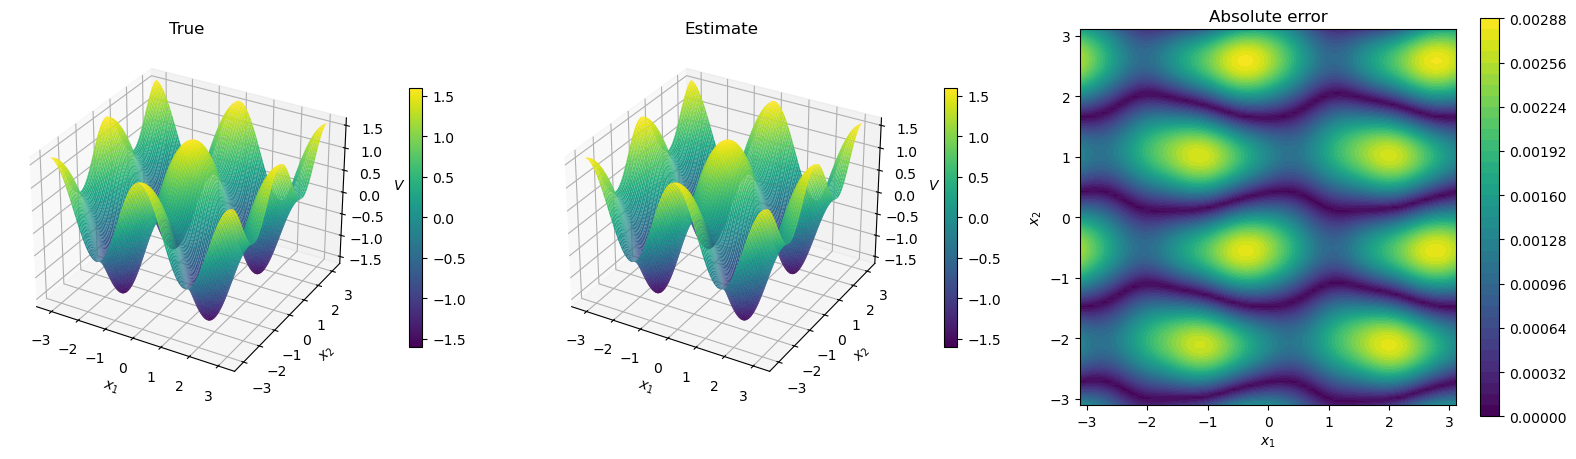

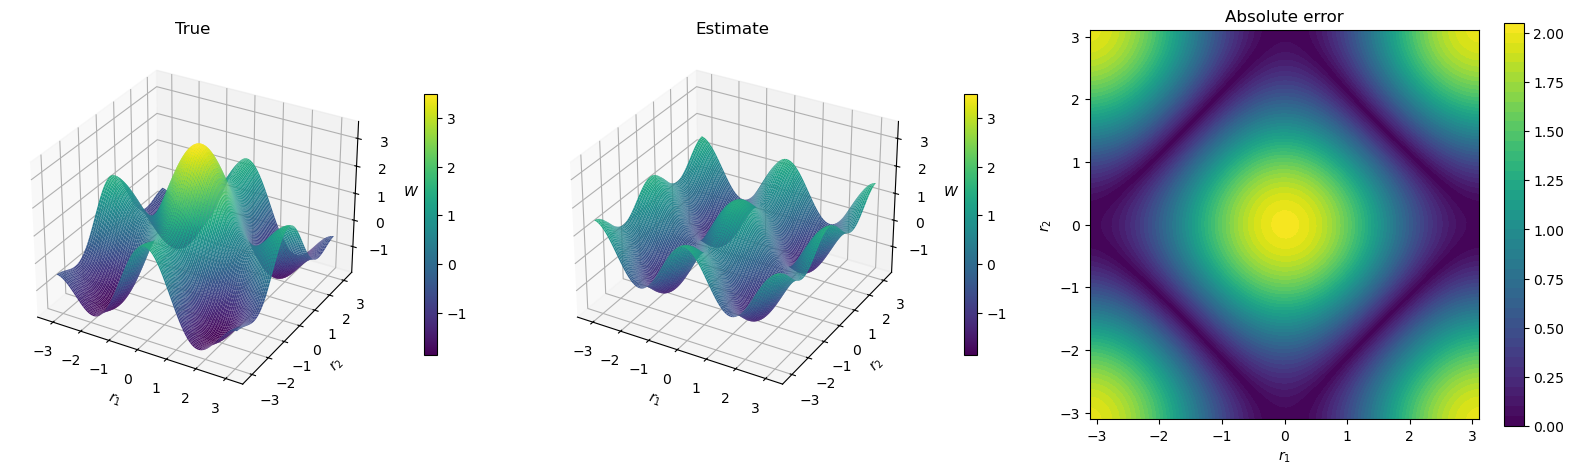

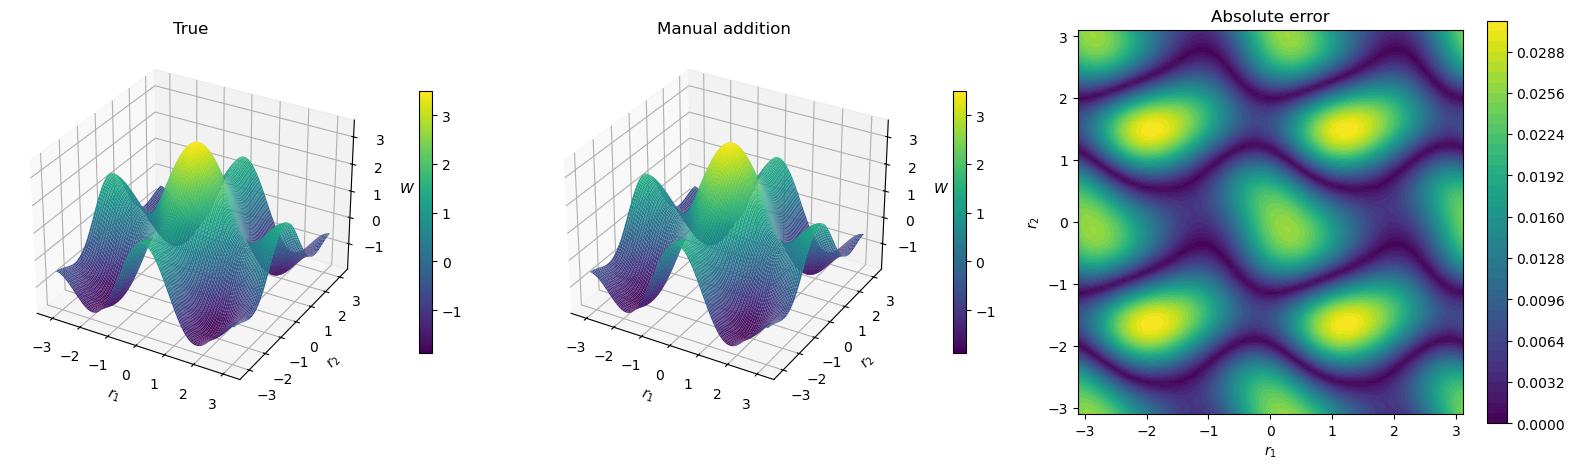

In [35]:
# Recover V,W from observed rho and phi.
# f_delta = -A_rho(phi_t + H_god(phi) + Uprime(rho)).
# Finite periodic Gaussian kernel-center approximation.

data = np.load(data_dir/"trajectory.npz")
x,t = data["x"],data["t"]
rho,phi,U_data = data["rho"],data["phi"],data["Uprime_rho"]
L,dx = float(data["L"]),float(data["dx"])
N,Nt = len(x),len(t)
assert Nt>=3 and rho.shape==phi.shape==U_data.shape==(Nt,N,N)
assert np.allclose(np.diff(t),t[1]-t[0])

X,Y = np.meshgrid(x,x,indexing="ij")
points = np.column_stack((X.ravel(),Y.ravel()))
lags = np.arange(N)*dx
S1,S2 = np.meshgrid(lags,lags,indexing="ij")
lag_points = np.column_stack((S1.ravel(),S2.ravel()))

def Dx(F,axis):
    return (np.roll(F,-1,axis=axis)-np.roll(F,1,axis=axis))/(2*dx)

def Dxx(F,axis):
    return (np.roll(F,-1,axis=axis)-2*F+np.roll(F,1,axis=axis))/dx**2

def A_of_F(r,F):
    return (Dx(r,0)*Dx(F,0)+Dx(r,1)*Dx(F,1)
            +r*(Dxx(F,0)+Dxx(F,1)))

def H_periodic(F):
    out = np.zeros_like(F)
    for axis in (0,1):
        dm = (F-np.roll(F,1,axis=axis))/dx
        dp = (np.roll(F,-1,axis=axis)-F)/dx
        out += 0.5*np.maximum(np.maximum(dm,0)**2,np.minimum(dp,0)**2)
    return out

# -------------------- Periodic Gaussian kernels --------------------
z = np.linspace(-L,L,p["centers"],endpoint=False)
Z1,Z2 = np.meshgrid(z,z,indexing="ij")
Z = np.column_stack((Z1.ravel(),Z2.ravel()))

def gaussian_1d(q,ell,deriv):
    q = (q+L)%(2*L)-L
    J = int(np.ceil((L+9*ell)/(2*L)))
    out = np.zeros_like(q)
    for j in range(-J,J+1):
        r = q+2*L*j
        g = np.exp(-r*r/(2*ell**2))
        if deriv==0: out += g
        elif deriv==1: out += -r*g/ell**2
        else: out += (r*r/ell**4-1/ell**2)*g
    return out

def kernel(P,Z,ell,deriv=0):
    q = P[:,None,:]-Z[None,:,:]
    a = gaussian_1d(q[:,:,0],ell,0)
    b = gaussian_1d(q[:,:,1],ell,0)
    if deriv==0:
        return a*b-(np.sqrt(2*np.pi)*ell/(2*L))**2
    if deriv==1:
        return gaussian_1d(q[:,:,0],ell,1)*b
    if deriv==2:
        return a*gaussian_1d(q[:,:,1],ell,1)
    if deriv==3:
        return (gaussian_1d(q[:,:,0],ell,2)*b
                +a*gaussian_1d(q[:,:,1],ell,2))
    raise ValueError("Invalid derivative index")

def whiten(ell):
    G = kernel(Z,Z,ell)
    s,U = eigh((G+G.T)/2)
    keep = s>p["rank_tol"]*s.max()
    return U[:,keep]/np.sqrt(s[keep])

QV,QW = whiten(p["ell_V"]),whiten(p["ell_W"])
nV,nW = QV.shape[1],QW.shape[1]
VB = [kernel(points,Z,p["ell_V"],d)@QV for d in (1,2,3)]
FW = [
    np.fft.fft2(
        (kernel(lag_points,Z,p["ell_W"],d)@QW).reshape(N,N,nW),
        axes=(0,1))
    for d in (1,2,3)
]

# -------------------- Uniform interior-time sampling --------------------
rng = np.random.default_rng(p["seed"])
total = (Nt-2)*N*N
M = min(p["M"],total)
chosen = rng.choice(total,size=M,replace=False)
it,ix,iy = np.unravel_index(chosen,(Nt-2,N,N))
it += 1

B = np.zeros((M,nV+nW))
f,w = np.zeros(M),np.zeros(M)
truth_A,psi_A = np.zeros(M),np.zeros(M)
invisible_error = 0.0

# Spectral derivatives of saved truth: diagnostics only.
freq = 2*np.pi*np.fft.fftfreq(N,d=dx)
K1,K2 = np.meshgrid(freq,freq,indexing="ij")

def spectral_fields(F):
    FF = np.fft.fft2(F)
    return [np.fft.ifft2(mult*FF).real for mult in
            (1j*K1,1j*K2,-K1*K1-K2*K2)]

Vref = data["V"]
VP = spectral_fields(Vref)
Wlags,psi_lags = data["W_lags"],data["psi_lags"]
FT = [np.fft.fft2(a) for a in spectral_fields(Wlags)]
FP = [np.fft.fft2(a) for a in spectral_fields(psi_lags)]
Fpsi = np.fft.fft2(psi_lags)

for count,l in enumerate(np.unique(it)):
    ids = np.flatnonzero(it==l)
    i,j = ix[ids],iy[ids]
    flat = i*N+j
    r = rho[l]
    rx,ry = Dx(r,0),Dx(r,1)
    rc,rxc,ryc = r[i,j],rx[i,j],ry[i,j]

    phi_t = (phi[l+1]-phi[l-1])/(t[l+1]-t[l-1])
    f_field = -A_of_F(r,phi_t+H_periodic(phi[l])+U_data[l])
    f[ids] = f_field[i,j]
    w[ids] = rc*dx**2*(t[1]-t[0])*total/M

    B[ids,:nV] = (rxc[:,None]*VB[0][flat]
                   +ryc[:,None]*VB[1][flat]
                   +rc[:,None]*VB[2][flat])

    Fr = np.fft.fft2(r)
    C = [dx**2*np.fft.ifft2(
        Fr[:,:,None]*F,axes=(0,1)).real[i,j] for F in FW]
    B[ids,nV:] = (rxc[:,None]*C[0]+ryc[:,None]*C[1]+rc[:,None]*C[2])

    CT = [dx**2*np.fft.ifft2(Fr*F).real[i,j] for F in FT]
    truth_A[ids] = (rxc*(VP[0][i,j]+CT[0])
                    +ryc*(VP[1][i,j]+CT[1])
                    +rc*(VP[2][i,j]+CT[2]))

    CP = [dx**2*np.fft.ifft2(Fr*F).real[i,j] for F in FP]
    psi_A[ids] = rxc*CP[0]+ryc*CP[1]+rc*CP[2]
    invisible_error = max(invisible_error,np.max(np.abs(
        dx**2*np.fft.ifft2(Fr*Fpsi).real)))

    if (count+1)%50==0:
        print(f"Prepared {count+1}/{len(np.unique(it))} time slices")

# -------------------- Joint RKHS regression --------------------
A = B.T@(w[:,None]*B)
b = B.T@(w*f)
A = (A+A.T)/2
reg = np.r_[np.full(nV,p["lam_V"]),np.full(nW,p["lam_W"])]
H = A+np.diag(reg)
c = cho_solve(cho_factor(H,lower=True),b)
cV,cW = QV@c[:nV],QW@c[nV:]

def relative_residual(e):
    return np.sqrt(np.dot(w,e*e)/max(np.dot(w*f,f),1e-28))

e = B@c-f
residual = relative_residual(e)
truth_residual = relative_residual(truth_A-f)
alternative_residual = relative_residual(e+psi_A)

Vhat = (kernel(points,Z,p["ell_V"])@cV).reshape(N,N)
What = (kernel(points,Z,p["ell_W"])@cW).reshape(N,N)

# Shift saved lag-grid fields onto the spatial grid.
phase = np.exp(1j*(K1*x[0]+K2*x[0]))
Wref = np.fft.ifft2(np.fft.fft2(Wlags)*phase).real
psi = np.fft.ifft2(np.fft.fft2(psi_lags)*phase).real
Wrepresentative = Wref-psi
Walternative = What+psi

def relerr(F,G):
    return np.linalg.norm(F-G)/max(np.linalg.norm(G),1e-14)

print(f"Kernel dimensions: V={nV}, W={nW}")
print(f"Truth Adelta residual:       {truth_residual:.6e}")
print(f"Estimated Adelta residual:   {residual:.6e}")
print(f"Alternative residual:       {alternative_residual:.6e}")
print(f"Maximum |psi*rho|:          {invisible_error:.3e}")
print(f"V relative L2 error:        {relerr(Vhat,Vref):.4e}")
print(f"W error, full truth:        {relerr(What,Wref):.4e}")
print(f"W error, representative:    {relerr(What,Wrepresentative):.4e}")
print(f"W error, after manual add:  {relerr(Walternative,Wref):.4e}")

# -------------------- Figures --------------------
Xplot,Yplot = np.meshgrid(x,x,indexing="ij")

for name,truth,estimate in [
    ("V",Vref,Vhat),
    ("W",Wref,What),
    ("W_alternative",Wref,Walternative)
]:
    lo = min(truth.min(),estimate.min())
    hi = max(truth.max(),estimate.max())
    labels = (r"$x_1$",r"$x_2$") if name=="V" else (r"$r_1$",r"$r_2$")

    fig = plt.figure(figsize=(16,4.5))
    for j,(F,title) in enumerate([
        (truth,"True"),
        (estimate,"Manual addition" if name=="W_alternative" else "Estimate")
    ]):
        ax = fig.add_subplot(1,3,j+1,projection="3d")
        surf = ax.plot_surface(
            Xplot,Yplot,F,cmap="viridis",vmin=lo,vmax=hi,
            rcount=len(x),ccount=len(x),linewidth=0,antialiased=True)
        ax.set(xlabel=labels[0],ylabel=labels[1],
               zlabel=r"$V$" if name=="V" else r"$W$",
               title=title,zlim=(lo,hi))
        ax.view_init(elev=30,azim=-60)
        fig.colorbar(surf,ax=ax,shrink=0.65,pad=0.1)

    ax = fig.add_subplot(1,3,3)
    im = ax.contourf(x,x,np.abs(estimate-truth).T,
                     levels=40,cmap="viridis")
    ax.set(xlabel=labels[0],ylabel=labels[1],
           title="Absolute error",aspect="equal")
    fig.colorbar(im,ax=ax)

    fig.tight_layout()
    savefig(fig,name)
    plt.show()

np.savez(data_dir/"reconstruction.npz",
    x=x,V_hat=Vhat,W_hat=What,W_alternative=Walternative,
    Z=Z,cV=cV,cW=cW,residual=residual,
    truth_residual=truth_residual,
    alternative_residual=alternative_residual,
    invisible_error=invisible_error,**p)